In [16]:
import os
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from collections import Counter

In [17]:
dataset_path = "ECG"

record = wfdb.rdrecord(
    os.path.join(dataset_path, "100")
)

signals = record.p_signal

annotation = wfdb.rdann(
    os.path.join(dataset_path, "100"),
    "atr"
)

print("ECG Shape:", signals.shape)
print("Sampling Frequency:", record.fs)
print("Signal Names:", record.sig_name)

print("Annotation Count:", len(annotation.sample))
print("Annotation Symbols:", set(annotation.symbol))

ECG Shape: (650000, 2)
Sampling Frequency: 360
Signal Names: ['MLII', 'V5']
Annotation Count: 2274
Annotation Symbols: {'V', 'A', '+', 'N'}


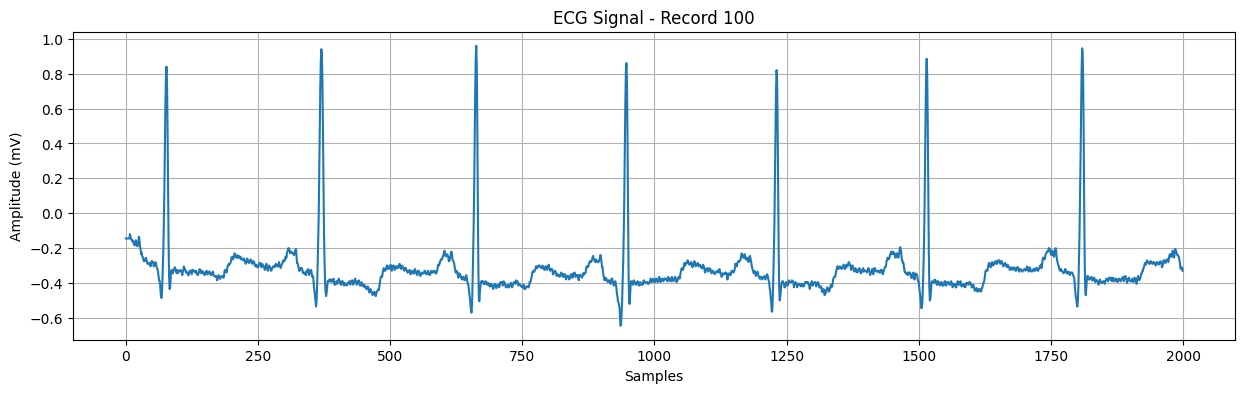

In [18]:
plt.figure(figsize=(15, 4))

plt.plot(signals[:2000, 0])

plt.title("ECG Signal - Record 100")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")

plt.grid()
plt.show()

In [19]:
symbol_counts = Counter(annotation.symbol)

print("ECG Annotation Counts:")

for symbol, count in symbol_counts.items():
    print(symbol, ":", count)

ECG Annotation Counts:
+ : 1
N : 2239
A : 33
V : 1


In [20]:
normal_beats = []
abnormal_beats = []

window = 180

for sample, symbol in zip(
    annotation.sample,
    annotation.symbol
):

    if sample - window < 0:
        continue

    if sample + window >= len(signals):
        continue

    beat = signals[
        sample-window:sample+window, 0
    ]

    if symbol == 'N':
        normal_beats.append(beat)

    elif symbol in ['A', 'V']:
        abnormal_beats.append(beat)


normal_beats = np.array(normal_beats)
abnormal_beats = np.array(abnormal_beats)

print("Normal Beats:", normal_beats.shape)
print("Abnormal Beats:", abnormal_beats.shape)

Normal Beats: (2237, 360)
Abnormal Beats: (34, 360)


In [21]:
X_train, X_val = train_test_split(
    normal_beats,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)

Training Data: (1789, 360)
Validation Data: (448, 360)


In [22]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_abnormal_scaled = scaler.transform(abnormal_beats)

print("Training Data:", X_train_scaled.shape)
print("Validation Data:", X_val_scaled.shape)
print("Abnormal Data:", X_abnormal_scaled.shape)

Training Data: (1789, 360)
Validation Data: (448, 360)
Abnormal Data: (34, 360)


In [23]:
input_dim = X_train_scaled.shape[1]

# Encoder
input_layer = Input(shape=(input_dim,))

encoder = Dense(128, activation='relu')(input_layer)

encoder = Dense(64, activation='relu')(encoder)

encoded = Dense(32, activation='relu')(encoder)

# Decoder
decoder = Dense(64, activation='relu')(encoded)

decoder = Dense(128, activation='relu')(decoder)

output_layer = Dense(
    input_dim,
    activation='sigmoid'
)(decoder)

# Create Autoencoder
autoencoder = Model(
    input_layer,
    output_layer
)

# Compile Model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 360)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        46,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 360)            │        46,440 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,416 (443.03 KB)

 Trainable params: 113,416 (443.03 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=32,
    validation_data=(
        X_val_scaled,
        X_val_scaled
    ),
    shuffle=True
)

Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0124 - val_loss: 0.0077
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0058 - val_loss: 0.0037
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0037 - val_loss: 0.0034
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0030 - val_loss: 0.0025
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0024 - val_loss: 0.0022
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0023 - val_loss: 0.0024
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0020 - val_loss: 0.0022
Epoch 9/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0019 - val_loss: 0.0017
Epoch 10/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 11/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0017 - val_loss: 0.0018
Epoch 12/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016 - val_lo

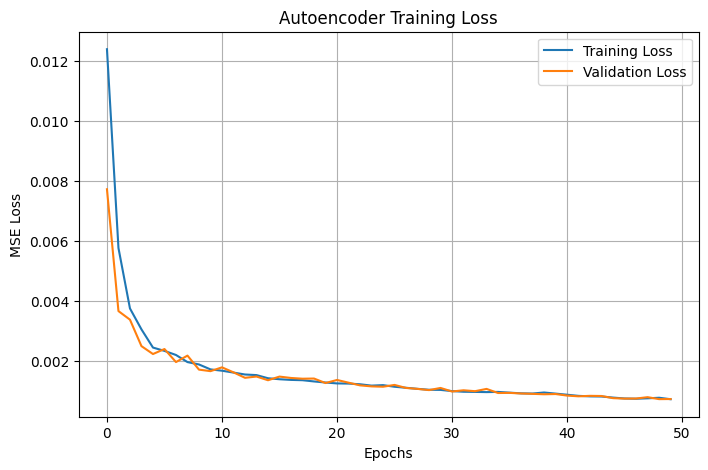

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid()
plt.show()

In [26]:
train_predictions = autoencoder.predict(
    X_train_scaled
)

train_errors = np.mean(
    np.square(
        X_train_scaled - train_predictions
    ),
    axis=1
)

print("Mean Training Error:", np.mean(train_errors))

print("Maximum Training Error:", np.max(train_errors))

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Mean Training Error: 0.000708712215389444
Maximum Training Error: 0.02851801087878967


In [27]:
threshold = np.percentile(
    train_errors,
    95
)

print("Anomaly Threshold:", threshold)

Anomaly Threshold: 0.0012224179869048902


In [28]:
# Reconstruct validation ECG
val_predictions = autoencoder.predict(
    X_val_scaled
)

# Reconstruct abnormal ECG
abnormal_predictions = autoencoder.predict(
    X_abnormal_scaled
)

# Calculate reconstruction errors
val_errors = np.mean(
    np.square(
        X_val_scaled - val_predictions
    ),
    axis=1
)

abnormal_errors = np.mean(
    np.square(
        X_abnormal_scaled - abnormal_predictions
    ),
    axis=1
)

# Predict anomalies
val_predictions_label = (
    val_errors > threshold
).astype(int)

abnormal_predictions_label = (
    abnormal_errors > threshold
).astype(int)

print(
    "Normal ECG detected as anomaly:",
    np.sum(val_predictions_label)
)

print(
    "Abnormal ECG detected as anomaly:",
    np.sum(abnormal_predictions_label)
)

print(
    "Total abnormal beats:",
    len(abnormal_beats)
)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
Normal ECG detected as anomaly: 24
Abnormal ECG detected as anomaly: 34
Total abnormal beats: 34


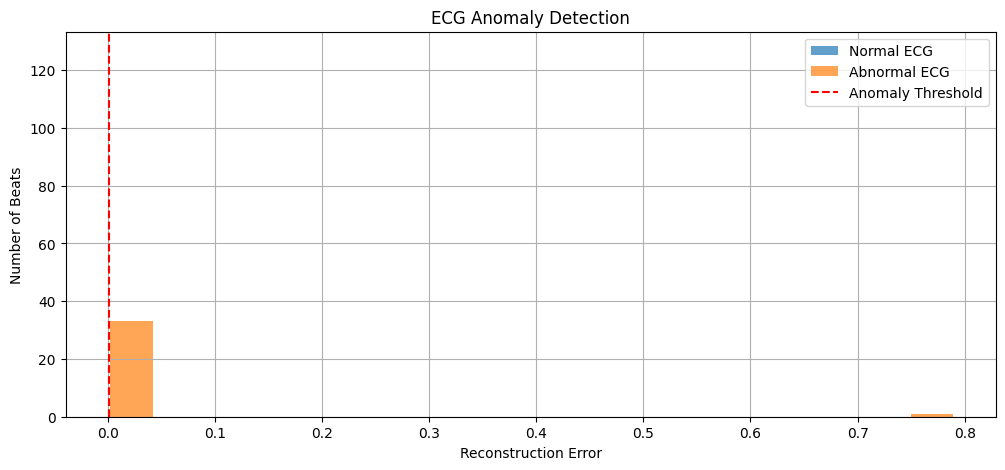

In [29]:
plt.figure(figsize=(12, 5))

plt.hist(
    val_errors,
    bins=30,
    alpha=0.7,
    label="Normal ECG"
)

plt.hist(
    abnormal_errors,
    bins=20,
    alpha=0.7,
    label="Abnormal ECG"
)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("ECG Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Beats")

plt.legend()
plt.grid()
plt.show()

In [30]:
# Actual labels
y_true = np.concatenate([
    np.zeros(len(X_val_scaled)),
    np.ones(len(X_abnormal_scaled))
])

# Predicted labels
y_pred = np.concatenate([
    val_predictions_label,
    abnormal_predictions_label
])

# Accuracy
accuracy = accuracy_score(
    y_true,
    y_pred
)

print("Accuracy:", accuracy)

# Confusion Matrix
print("\nConfusion Matrix:")

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

# Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Normal",
            "Abnormal"
        ],
        zero_division=0
    )
)

Accuracy: 0.950207468879668

Confusion Matrix:
[[424  24]
 [  0  34]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97       448
    Abnormal       0.59      1.00      0.74        34

    accuracy                           0.95       482
   macro avg       0.79      0.97      0.86       482
weighted avg       0.97      0.95      0.96       482



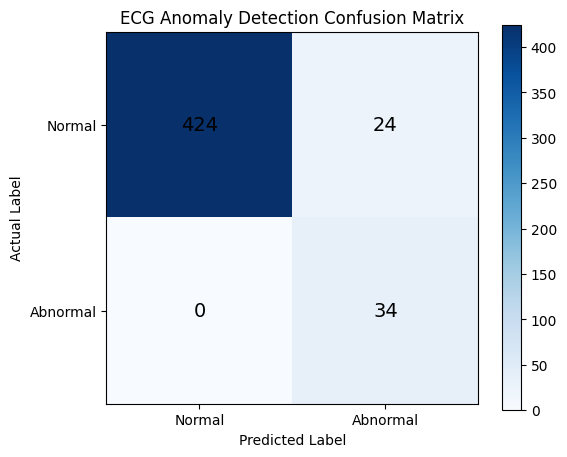

In [31]:
plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')

plt.title("ECG Anomaly Detection Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Abnormal"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center',
            fontsize=14
        )

plt.colorbar()
plt.show()

In [32]:
autoencoder.save("ecg_autoencoder.keras")

print("ECG Autoencoder Model Saved Successfully!")

ECG Autoencoder Model Saved Successfully!
